# AAPL: price-only models versus sentiment-enhanced GRU
This is a separate experiment from the AAME reproduction. All four models use the same chronological AAPL observations, 70/15/15 train/development-test/final-validation split, training-only price normalization, and one-step same-day Open/High/Low → Close task. This is closing-price estimation, not an advance next-day forecast; the daily High and Low are not known until the end of the session.

Input news file: `AAPL_FinBERT_Sentiment_2013_2022.csv` (columns `date`, `Sentiment`; optional `source`). Use only news you are authorized to process for this research. The news file is assumed to have fixed, pretrained FinBERT scores and correct publication calendar dates. The code excludes publication on the target date and later. News availability and source differences may still affect results. Do not use the final validation set to select models or feature settings.

## Yahoo Finace Libaray

In [1]:
!pip install -q yfinance

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Download AAPL once; exploratory plots use training dates only
stock_symbol = "AAPL"
start_date = "2013-01-01"
end_date = "2023-01-01"

raw_download = yf.download(
    stock_symbol, start=start_date, end=end_date,
    auto_adjust=False, progress=False
)

if raw_download.empty:
    raise ValueError("AAPL download failed.")
if isinstance(raw_download.columns, pd.MultiIndex):
    raw_download.columns = raw_download.columns.get_level_values(0)

raw_download = raw_download.sort_index()
raw_download.index.name = "Date"

# Keep exploratory plots and outlier checks away from the holdout
stock_data = raw_download.iloc[:int(len(raw_download) * 0.70)].copy()
stock_data = stock_data.reset_index()


## Plot historical data

In [3]:
import time
from datetime import datetime
import plotly.express as px
import pandas as pd

# Fix yfinance MultiIndex columns
if isinstance(stock_data.columns, pd.MultiIndex):
    stock_data.columns = stock_data.columns.get_level_values(0)

# Make sure Date is a column
if "Date" not in stock_data.columns:
    stock_data = stock_data.reset_index()

def plot_stock_data(data, title):
    '''Function for plotting stock data'''
    plot = px.line(
        data,
        x="Date",
        y="Close",
        hover_name="Date",
        line_shape="linear",
        title=title
    )
    return plot

plot_stock_data(stock_data[-30:], "AAPL Stock Prices")


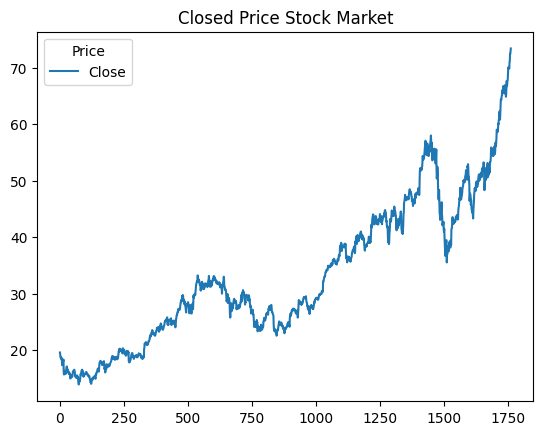

In [4]:
stock_data[['Close']].plot()
plt.title("Closed Price Stock Market")
plt.show()

## Outlier checking

In [5]:
# Create df from the existing stock dataset
df = stock_data.copy()

# Convert the Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Display the dataset
df


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2013-01-02,16.554533,19.608213,19.821428,19.343929,19.779285,560518000
1,2013-01-03,16.345575,19.360714,19.631071,19.321428,19.567142,352965200
2,2013-01-04,15.890279,18.821428,19.236786,18.779642,19.177500,594333600
3,2013-01-07,15.796803,18.710714,18.903570,18.400000,18.642857,484156400
4,2013-01-08,15.839320,18.761070,18.996071,18.616072,18.900356,458707200
...,...,...,...,...,...,...,...
1757,2019-12-24,68.350365,71.067497,71.222504,70.730003,71.172501,48478800
1758,2019-12-26,69.706451,72.477501,72.495003,71.175003,71.205002,93121200
1759,2019-12-27,69.680008,72.449997,73.492500,72.029999,72.779999,146266000
1760,2019-12-30,70.093567,72.879997,73.172501,71.305000,72.364998,144114400


In [6]:
# Specify the column to analyze for outliers
column_name = 'Open'

# Calculate the IQR (Interquartile Range)
Q1 = df[column_name].quantile(0.25)
Q3 = df[column_name].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify and count outliers
outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
num_outliers = len(outliers)

# Display the number of outliers
print(f'Number of outliers in {column_name}: {num_outliers}')


Number of outliers in Open: 3


In [7]:
# Specify the column to analyze for outliers
column_name = 'Close'

# Calculate the IQR (Interquartile Range)
Q1 = df[column_name].quantile(0.25)
Q3 = df[column_name].quantile(0.75)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify and count outliers
outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
num_outliers = len(outliers)

# Display the number of outliers
print(f'Number of outliers in {column_name}: {num_outliers}')


Number of outliers in Close: 4


/usr/local/lib/python3.13/dist-packages/seaborn/_base.py:1608: UserWarning:

Vertical orientation ignored with only `x` specified.

/tmp/ipykernel_11106/2118448779.py:10: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




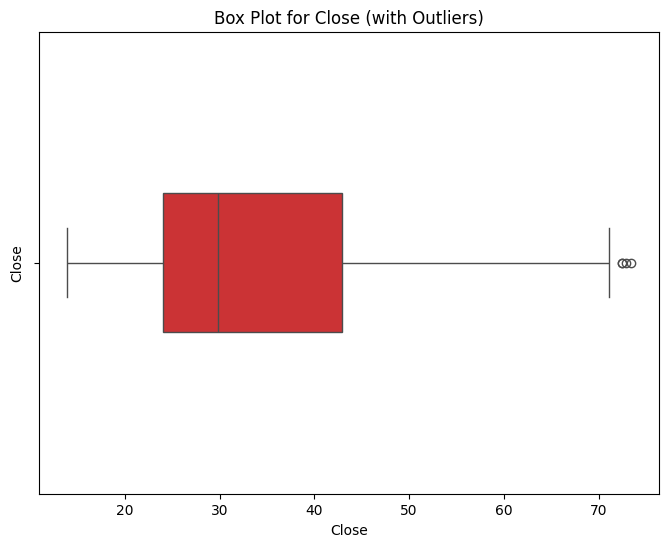

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns


# Specify the column to visualize outliers
column_name = 'Close'

# Create a box plot to visualize outliers
plt.figure(figsize=(8, 6))
sns.boxplot(x=df[column_name], orient='v', width=0.3, palette='Set1')
plt.title(f'Box Plot for {column_name} (with Outliers)')
plt.ylabel(column_name)
plt.show()


## Shared AAPL preprocessing (70% training / 15% testing / 15% final validation)


In [9]:
import torch
import numpy as np
import pandas as pd
import yfinance as yf
from google.colab import files

torch.manual_seed(42)
np.random.seed(42)

# Reuse the AAPL download from the first data cell.
# Exploration used only the training portion.
raw = raw_download.copy()

raw = raw.rename(
    columns={"Adj Close": "Adjusted Close"}
)

columns_to_normalize = [
    "Low", "Open", "Volume",
    "High", "Close", "Adjusted Close"
]

raw = raw[columns_to_normalize].sort_index().copy()
raw.index.name = "Date"

if raw.isna().any().any():
    raise ValueError("Missing AAPL stock values")

# Split chronologically: 70/15/15
train_size = int(len(raw) * 0.70)
test_size = int(len(raw) * 0.15)

train_raw = raw.iloc[:train_size].copy()
test_raw = raw.iloc[
    train_size:train_size + test_size
].copy()
val_raw = raw.iloc[
    train_size + test_size:
].copy()

# Export original stock data
train_raw.to_csv("AAPL_Training.csv")
test_raw.to_csv("AAPL_Testing.csv")
val_raw.to_csv("AAPL_Validation.csv")

print("Training:", len(train_raw))
print("Testing:", len(test_raw))
print("Validation:", len(val_raw))

# Normalize using ONLY training data
train_tensor = torch.tensor(
    train_raw.to_numpy(),
    dtype=torch.float32
)

mean = train_tensor.mean(dim=0)
std = train_tensor.std(dim=0)
std = torch.where(
    std == 0,
    torch.ones_like(std),
    std
)

train_data = (
    train_raw - mean.numpy()
) / std.numpy()

test_data = (
    test_raw - mean.numpy()
) / std.numpy()

train_data = train_data.reset_index()
test_data = test_data.reset_index()

feature_columns = ["Low", "Open", "High"]
target_column = "Close"

# Prepare tensors shared by all three models
train_features = torch.tensor(
    train_data[feature_columns].to_numpy(),
    dtype=torch.float32
)

train_target = torch.tensor(
    train_data[target_column].to_numpy(),
    dtype=torch.float32
)

test_features = torch.tensor(
    test_data[feature_columns].to_numpy(),
    dtype=torch.float32
)

test_target = torch.tensor(
    test_data[target_column].to_numpy(),
    dtype=torch.float32
)

# Download datasets immediately
files.download("AAPL_Training.csv")
files.download("AAPL_Testing.csv")
files.download("AAPL_Validation.csv")


Training: 1762
Testing: 377
Validation: 379


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## LSTM

LSTM Epoch 10/100 | Train: 0.96127 | Test: 34.30524
LSTM Epoch 20/100 | Train: 0.87840 | Test: 32.73280
LSTM Epoch 30/100 | Train: 0.73690 | Test: 29.70185
LSTM Epoch 40/100 | Train: 0.51265 | Test: 24.95009
LSTM Epoch 50/100 | Train: 0.23330 | Test: 18.94339
LSTM Epoch 60/100 | Train: 0.03384 | Test: 13.09400
LSTM Epoch 70/100 | Train: 0.02203 | Test: 9.76259
LSTM Epoch 80/100 | Train: 0.01886 | Test: 10.04296
LSTM Epoch 90/100 | Train: 0.01048 | Test: 11.03317
LSTM Epoch 100/100 | Train: 0.01092 | Test: 10.84203


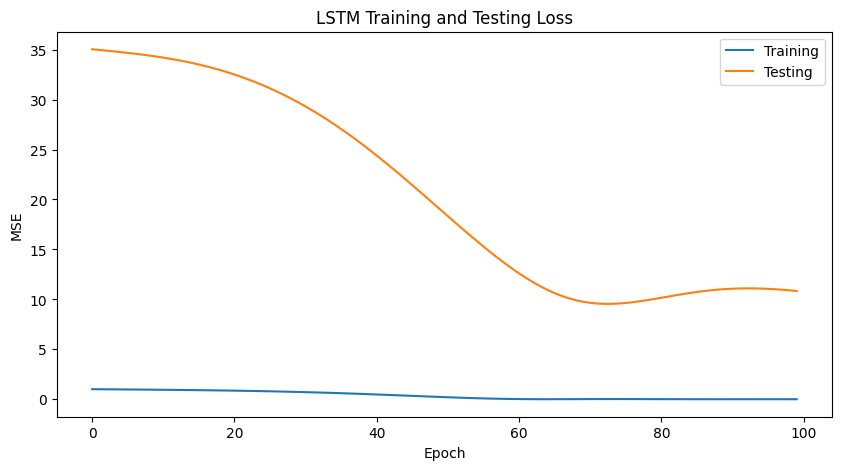

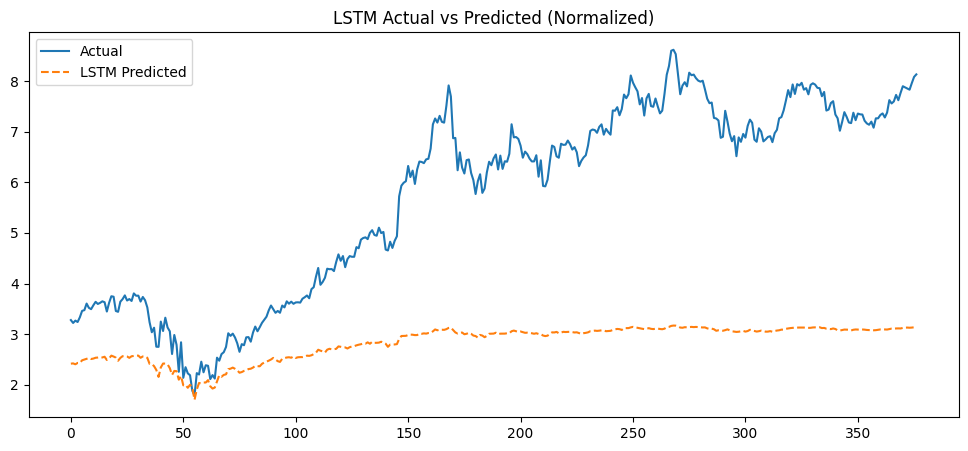

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)

class LSTMModel(nn.Module):
    def __init__(
        self, input_size, hidden_size,
        output_size, num_layers
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True
        )

        self.fc_output = nn.Linear(
            hidden_size, output_size
        )

    def forward(self, x):
        _, (hn, _) = self.lstm(x)
        return self.fc_output(hn[-1, :, :])


model_lstm = LSTMModel(3, 64, 1, 2)

criterion_lstm = nn.MSELoss()
optimizer_lstm = optim.Adam(
    model_lstm.parameters(),
    lr=0.001
)

train_losses_lstm = []
test_losses_lstm = []

for epoch in range(100):
    model_lstm.train()
    optimizer_lstm.zero_grad()

    outputs_lstm = model_lstm(
        train_features.unsqueeze(1)
    )

    loss_lstm = criterion_lstm(
        outputs_lstm,
        train_target.unsqueeze(1)
    )

    loss_lstm.backward()
    optimizer_lstm.step()

    train_losses_lstm.append(loss_lstm.item())

    model_lstm.eval()

    with torch.no_grad():
        pred = model_lstm(
            test_features.unsqueeze(1)
        )

        test_loss = criterion_lstm(
            pred,
            test_target.unsqueeze(1)
        )

    test_losses_lstm.append(test_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"LSTM Epoch {epoch+1}/100 | "
            f"Train: {loss_lstm.item():.5f} | "
            f"Test: {test_loss.item():.5f}"
        )

# Final test predictions
model_lstm.eval()

with torch.no_grad():
    test_predictions_lstm = model_lstm(
        test_features.unsqueeze(1)
    ).squeeze(1).cpu().numpy()

# Training and testing loss graph
plt.figure(figsize=(10, 5))
plt.plot(train_losses_lstm, label="Training")
plt.plot(test_losses_lstm, label="Testing")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("LSTM Training and Testing Loss")
plt.legend()
plt.show()

# Actual vs predicted
plt.figure(figsize=(12, 5))
plt.plot(
    test_target.numpy(),
    label="Actual"
)
plt.plot(
    test_predictions_lstm,
    "--",
    label="LSTM Predicted"
)
plt.title("LSTM Actual vs Predicted (Normalized)")
plt.legend()
plt.show()


In [11]:
from sklearn.metrics import r2_score

# Calculate R2
r2 = r2_score(
    test_target.numpy(),
    test_predictions_lstm
)

print(f'R-squared: {r2}')


R-squared: -2.0528948307037354


## Transformer

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning:

enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)



Transformer Epoch 10/100 | Train: 0.11129 | Test: 14.76676
Transformer Epoch 20/100 | Train: 0.11437 | Test: 16.66803
Transformer Epoch 30/100 | Train: 0.03820 | Test: 13.85070
Transformer Epoch 40/100 | Train: 0.03204 | Test: 11.81258
Transformer Epoch 50/100 | Train: 0.02673 | Test: 10.97500
Transformer Epoch 60/100 | Train: 0.02076 | Test: 10.63241
Transformer Epoch 70/100 | Train: 0.01663 | Test: 10.26732
Transformer Epoch 80/100 | Train: 0.01607 | Test: 10.02764
Transformer Epoch 90/100 | Train: 0.01480 | Test: 10.12065
Transformer Epoch 100/100 | Train: 0.01245 | Test: 10.16007


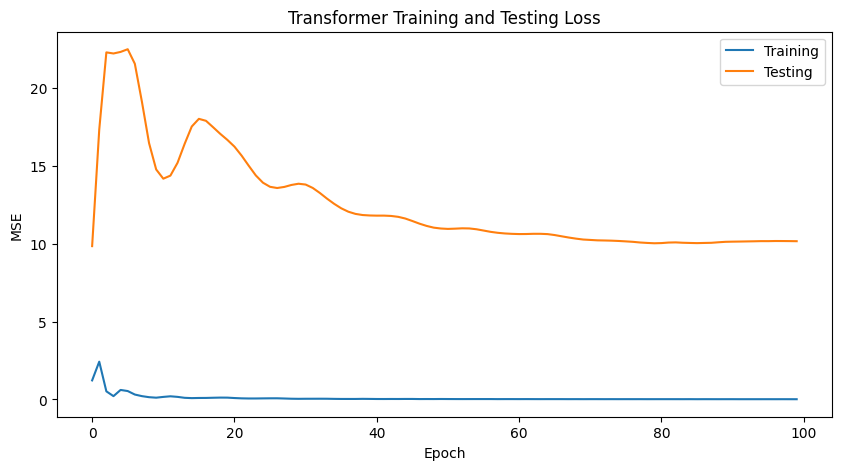

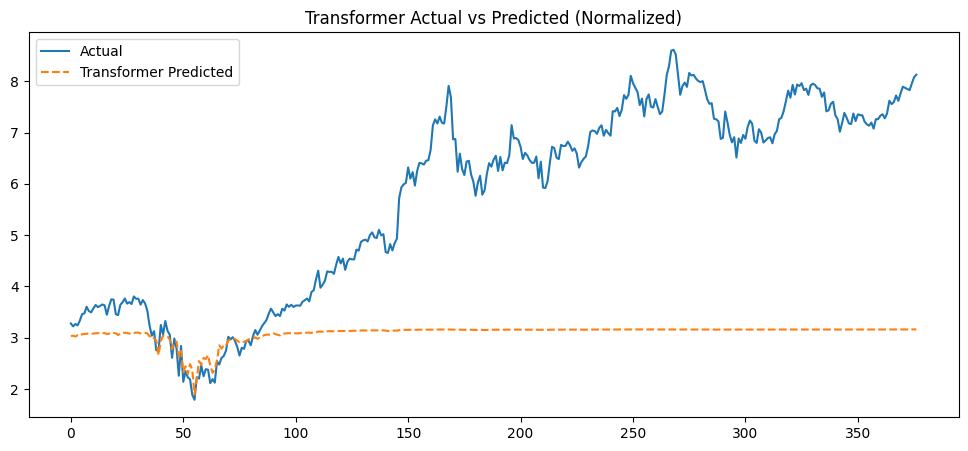

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

class TransformerModel(nn.Module):
    def __init__(
        self, input_size, hidden_size,
        output_size, num_layers,
        num_attention_heads
    ):
        super().__init__()

        self.embedding = nn.Linear(
            input_size, hidden_size
        )

        self.transformer = nn.Transformer(
            d_model=hidden_size,
            nhead=num_attention_heads,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers
        )

        self.fc_output = nn.Linear(
            hidden_size, output_size
        )

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(1, 0, 2)
        x = self.transformer(x, x)
        x = x.permute(1, 0, 2)

        return self.fc_output(
            x[:, -1, :]
        )


transformer_model = TransformerModel(
    input_size=3,
    hidden_size=64,
    output_size=1,
    num_layers=2,
    num_attention_heads=4
)

criterion_transformer = nn.MSELoss()

optimizer_transformer = optim.Adam(
    transformer_model.parameters(),
    lr=0.001
)

train_losses = []
test_losses = []

for epoch in range(100):

    transformer_model.train()
    optimizer_transformer.zero_grad()

    outputs = transformer_model(
        train_features.unsqueeze(1)
    )

    loss = criterion_transformer(
        outputs,
        train_target.unsqueeze(1)
    )

    loss.backward()
    optimizer_transformer.step()

    train_losses.append(loss.item())

    transformer_model.eval()

    with torch.no_grad():
        pred = transformer_model(
            test_features.unsqueeze(1)
        )

        test_loss = criterion_transformer(
            pred,
            test_target.unsqueeze(1)
        )

    test_losses.append(test_loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Transformer Epoch {epoch+1}/100 | "
            f"Train: {loss.item():.5f} | "
            f"Test: {test_loss.item():.5f}"
        )

# Final test predictions
transformer_model.eval()

with torch.no_grad():
    test_predictions = transformer_model(
        test_features.unsqueeze(1)
    ).squeeze(1).cpu().numpy()

# Training and testing loss graph
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training")
plt.plot(test_losses, label="Testing")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Transformer Training and Testing Loss")
plt.legend()
plt.show()

# Actual vs predicted
plt.figure(figsize=(12, 5))
plt.plot(
    test_target.numpy(),
    label="Actual"
)
plt.plot(
    test_predictions,
    "--",
    label="Transformer Predicted"
)
plt.title("Transformer Actual vs Predicted (Normalized)")
plt.legend()
plt.show()


## GRU — price-only baseline


Epoch [10/100], Training Loss: 0.799079
Epoch [20/100], Training Loss: 0.535170
Epoch [30/100], Training Loss: 0.212104
Epoch [40/100], Training Loss: 0.013487
Epoch [50/100], Training Loss: 0.028666
Epoch [60/100], Training Loss: 0.009414
Epoch [70/100], Training Loss: 0.007959
Epoch [80/100], Training Loss: 0.006929
Epoch [90/100], Training Loss: 0.006032
Epoch [100/100], Training Loss: 0.005863

========== GRU TEST RESULTS ==========
MAE (Normalized):  2.5412
MSE (Normalized):  8.7032
RMSE (Normalized): 2.9501
R-squared:         -1.4507

===== GRU ORIGINAL PRICE METRICS =====
MAE:  $32.4018
MSE:  1414.9764
RMSE: $37.6162
MAPE: 27.4718%
R²:   -1.4507


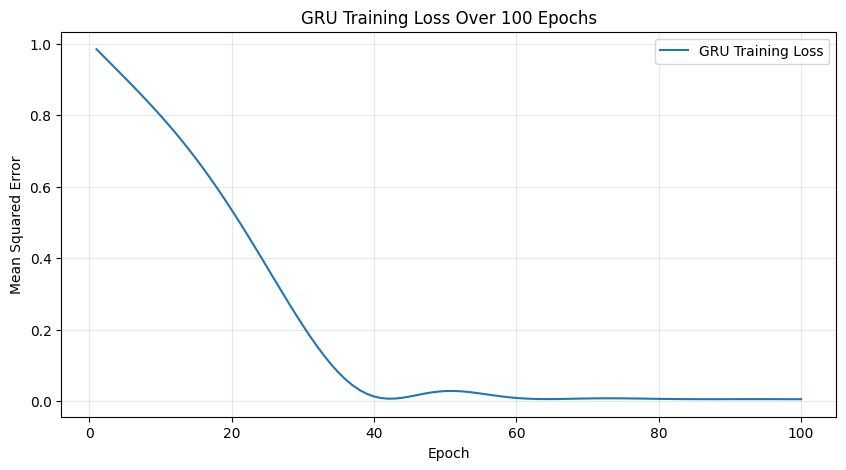

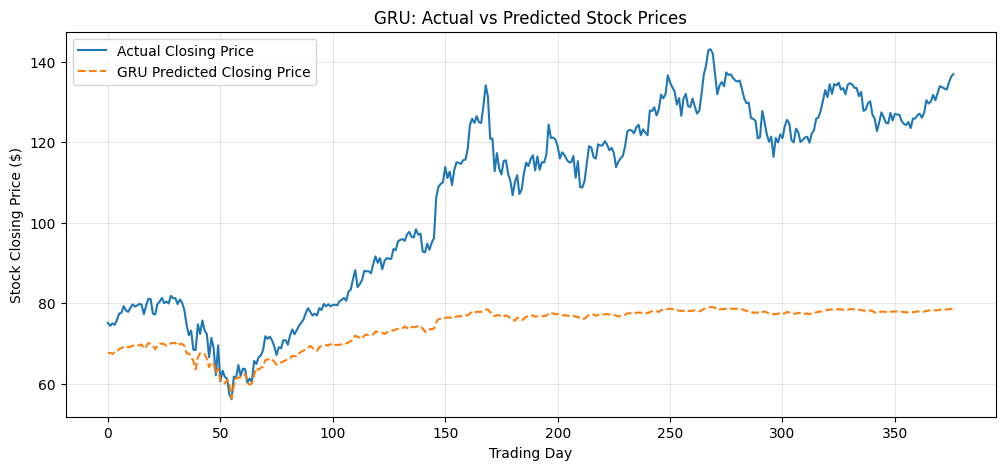


GRU training and evaluation complete!


In [13]:
# GRU MODEL - COMPARISON WITH LSTM AND TRANSFORMER


import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# DEFINE GRU MODEL

class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size,
                 num_layers, output_size):

        super(GRUModel, self).__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        gru_output, hidden = self.gru(x)
        return self.fc(gru_output[:, -1, :])


# DEFINE HYPERPARAMETERS

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Match LSTM and Transformer settings
input_size = 3
hidden_size = 64
num_layers = 2
output_size = 1

learning_rate = 0.001
num_epochs_gru = 100

# Create GRU model
model_gru = GRUModel(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=num_layers,
    output_size=output_size
)

# Define loss function and optimizer
criterion_gru = nn.MSELoss()

optimizer_gru = optim.Adam(
    model_gru.parameters(),
    lr=learning_rate
)


# TRAIN THE GRU MODEL

gru_train_losses = []

for epoch in range(num_epochs_gru):

    model_gru.train()
    optimizer_gru.zero_grad()

    # Forward pass
    outputs = model_gru(train_features.unsqueeze(1))

    # Calculate training loss
    loss = criterion_gru(
        outputs,
        train_target.unsqueeze(1)
    )

    # Backpropagation
    loss.backward()
    optimizer_gru.step()

    gru_train_losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs_gru}], "
            f"Training Loss: {loss.item():.6f}"
        )


# EVALUATE ON TEST DATASET

model_gru.eval()

with torch.no_grad():
    gru_predictions = model_gru(
        test_features.unsqueeze(1)
    )

gru_predictions = (
    gru_predictions.squeeze(1).cpu().numpy()
)

actual = test_target.cpu().numpy()


# CALCULATE NORMALIZED METRICS

gru_mae = mean_absolute_error(actual, gru_predictions)
gru_mse = mean_squared_error(actual, gru_predictions)
gru_rmse = np.sqrt(gru_mse)
gru_r2 = r2_score(actual, gru_predictions)

print("\n========== GRU TEST RESULTS ==========")

print(f"MAE (Normalized):  {gru_mae:.4f}")
print(f"MSE (Normalized):  {gru_mse:.4f}")
print(f"RMSE (Normalized): {gru_rmse:.4f}")
print(f"R-squared:         {gru_r2:.4f}")


# CONVERT BACK TO ORIGINAL STOCK PRICES

# Use normalization statistics from original preprocessing
close_index = columns_to_normalize.index('Close')

close_mean = mean[close_index].item()
close_std = std[close_index].item()

# Convert normalized values back to stock prices
actual_prices = actual * close_std + close_mean
predicted_prices = gru_predictions * close_std + close_mean

# Calculate original-price metrics
gru_mae_original = mean_absolute_error(
    actual_prices, predicted_prices
)

gru_mse_original = mean_squared_error(
    actual_prices, predicted_prices
)

gru_rmse_original = np.sqrt(gru_mse_original)

# Calculate MAPE using original stock prices
gru_mape = np.mean(
    np.abs(
        (actual_prices - predicted_prices) /
        np.maximum(np.abs(actual_prices), 1e-8)
    )
) * 100

print("\n===== GRU ORIGINAL PRICE METRICS =====")

print(f"MAE:  ${gru_mae_original:.4f}")
print(f"MSE:  {gru_mse_original:.4f}")
print(f"RMSE: ${gru_rmse_original:.4f}")
print(f"MAPE: {gru_mape:.4f}%")
print(f"R²:   {gru_r2:.4f}")


# VISUALIZE TRAINING LOSS

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, num_epochs_gru + 1),
    gru_train_losses,
    label="GRU Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("GRU Training Loss Over 100 Epochs")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# VISUALIZE ACTUAL VS PREDICTED STOCK PRICES

plt.figure(figsize=(12, 5))

plt.plot(
    actual_prices,
    label="Actual Closing Price"
)

plt.plot(
    predicted_prices,
    label="GRU Predicted Closing Price",
    linestyle="dashed"
)

plt.xlabel("Trading Day")
plt.ylabel("Stock Closing Price ($)")
plt.title("GRU: Actual vs Predicted Stock Prices")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\nGRU training and evaluation complete!")


## News features — add after the standard GRU
Run the previous news-collection and FinBERT notebook first, then upload its scored CSV when prompted. No validation features are built in this cell. The trailing windows use calendar dates strictly before each target date. Three separate flags distinguish missing news from neutral sentiment at each window. The seven-day count is log-transformed; the four numeric news features are standardized using only training rows. Flags remain 0/1.

In [14]:
import os
import pandas as pd
import numpy as np
import torch
from google.colab import files

NEWS_FILE = "AAPL_FinBERT_Sentiment_2013_2022.csv"

if not os.path.exists(NEWS_FILE):
    uploaded = files.upload()
    if NEWS_FILE not in uploaded:
        raise FileNotFoundError(f"Please upload {NEWS_FILE}")

scored_news = pd.read_csv(NEWS_FILE)

required = {"date", "Sentiment"}
if not required.issubset(scored_news.columns):
    raise ValueError("News CSV must contain date and Sentiment columns.")

# Preserve the supplied publication calendar date
scored_news["date"] = pd.to_datetime(
    scored_news["date"].astype(str).str[:10], errors="coerce"
)
scored_news["Sentiment"] = pd.to_numeric(
    scored_news["Sentiment"], errors="coerce"
)

if scored_news[["date", "Sentiment"]].isna().any().any():
    raise ValueError("Invalid date or sentiment in the news CSV.")
if not scored_news["Sentiment"].between(-1, 1).all():
    raise ValueError("Expected FinBERT sentiment scores in [-1, 1].")

scored_news = scored_news.sort_values("date").reset_index(drop=True)
if "relevant_text" in scored_news.columns:
    scored_news = scored_news.drop_duplicates(["date", "relevant_text"])

if scored_news.empty:
    raise ValueError("No scored news records.")

def make_news_features(dates, articles):
    dates = pd.DatetimeIndex(dates).normalize()
    if dates.tz is not None:
        dates = dates.tz_localize(None)

    articles = articles.sort_values("date")
    news_dates = pd.DatetimeIndex(articles["date"])
    scores = articles["Sentiment"].to_numpy(dtype=np.float64)
    prefix = np.r_[0.0, np.cumsum(scores)]
    result = pd.DataFrame(index=dates)

    for window in (1, 3, 7):
        left = news_dates.searchsorted(
            dates - pd.Timedelta(days=window), side="left"
        )
        right = news_dates.searchsorted(dates, side="left")
        count = right - left
        total = prefix[right] - prefix[left]

        result[f"Sentiment_{window}D"] = np.divide(
            total, count, out=np.zeros(len(dates)), where=count > 0
        )
        result[f"Has_News_{window}D"] = (count > 0).astype(float)

        if window == 7:
            result["Log_News_Count_7D"] = np.log1p(count)

    return result

news_numeric = [
    "Sentiment_1D", "Sentiment_3D", "Sentiment_7D",
    "Log_News_Count_7D"
]
news_flags = ["Has_News_1D", "Has_News_3D", "Has_News_7D"]
news_columns = news_numeric + news_flags

# Restrict development news to dates before the last development target
development_news = scored_news[
    scored_news["date"] < pd.Timestamp(test_raw.index[-1]).normalize()
].copy()

train_news = make_news_features(train_raw.index, development_news)
test_news = make_news_features(test_raw.index, development_news)

# Fit the news scaler on training data only
news_mean = train_news[news_numeric].mean()
news_std = train_news[news_numeric].std(ddof=0).replace(0, 1)

def news_tensor(frame):
    features = frame[news_columns].copy()
    features[news_numeric] = (
        features[news_numeric] - news_mean
    ) / news_std
    return torch.tensor(features.to_numpy(), dtype=torch.float32)

# All rows stay in chronological order, including those without news
assert len(train_news) == len(train_features)
assert len(test_news) == len(test_features)

train_features_enhanced = torch.cat(
    [train_features, news_tensor(train_news)], dim=1
)
test_features_enhanced = torch.cat(
    [test_features, news_tensor(test_news)], dim=1
)

print("Price-only training shape:", tuple(train_features.shape))
print("Enhanced training shape:", tuple(train_features_enhanced.shape))
print("Enhanced testing shape:", tuple(test_features_enhanced.shape))
print("Training news coverage:")
print((train_news[news_flags].mean() * 100).round(2))
print("Testing news coverage:")
print((test_news[news_flags].mean() * 100).round(2))


Saving AAPL_FinBERT_Sentiment_2013_2022.csv to AAPL_FinBERT_Sentiment_2013_2022.csv
Price-only training shape: (1762, 3)
Enhanced training shape: (1762, 10)
Enhanced testing shape: (377, 10)
Training news coverage:
Has_News_1D    67.99
Has_News_3D    88.54
Has_News_7D    97.84
dtype: float64
Testing news coverage:
Has_News_1D     82.49
Has_News_3D     98.41
Has_News_7D    100.00
dtype: float64


## Sentiment-enhanced GRU — same training configuration
The only architecture change is the input width (3 price features + 7 news features = 10 inputs). The standard GRU remains the price-only control.

Enhanced GRU Epoch 10/100 | Loss: 0.847746
Enhanced GRU Epoch 20/100 | Loss: 0.602141
Enhanced GRU Epoch 30/100 | Loss: 0.272654
Enhanced GRU Epoch 40/100 | Loss: 0.031048
Enhanced GRU Epoch 50/100 | Loss: 0.030451
Enhanced GRU Epoch 60/100 | Loss: 0.009264
Enhanced GRU Epoch 70/100 | Loss: 0.008480
Enhanced GRU Epoch 80/100 | Loss: 0.005901
Enhanced GRU Epoch 90/100 | Loss: 0.005507
Enhanced GRU Epoch 100/100 | Loss: 0.005072


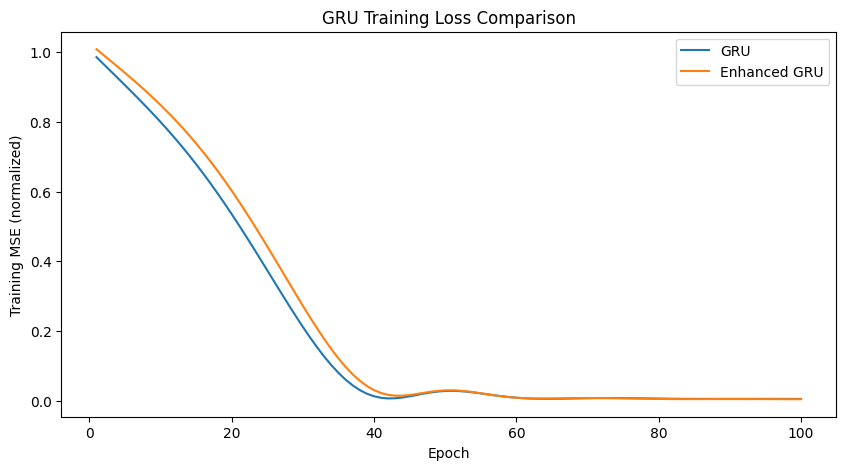

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

model_gru_enhanced = GRUModel(
    input_size=train_features_enhanced.shape[1],
    hidden_size=64,
    num_layers=2,
    output_size=1
)

criterion_enhanced = nn.MSELoss()
optimizer_enhanced = optim.Adam(
    model_gru_enhanced.parameters(), lr=0.001
)

enhanced_train_losses = []

for epoch in range(100):
    model_gru_enhanced.train()
    optimizer_enhanced.zero_grad()

    outputs = model_gru_enhanced(
        train_features_enhanced.unsqueeze(1)
    )
    loss = criterion_enhanced(outputs, train_target.unsqueeze(1))
    loss.backward()
    optimizer_enhanced.step()
    enhanced_train_losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Enhanced GRU Epoch {epoch+1}/100 | Loss: {loss.item():.6f}")

model_gru_enhanced.eval()
with torch.no_grad():
    enhanced_gru_predictions = model_gru_enhanced(
        test_features_enhanced.unsqueeze(1)
    ).squeeze(1).cpu().numpy()

plt.figure(figsize=(10, 5))
plt.plot(range(1, 101), gru_train_losses, label="GRU")
plt.plot(range(1, 101), enhanced_train_losses, label="Enhanced GRU")
plt.xlabel("Epoch")
plt.ylabel("Training MSE (normalized)")
plt.title("GRU Training Loss Comparison")
plt.legend()
plt.show()


## Compare all four models on the development test set


MODEL PERFORMANCE COMPARISON
              MAE ($)   MSE ($²)  RMSE ($)  MAPE (%)      R²
LSTM          36.9382  1762.7046   41.9846   31.7554 -2.0529
Transformer   34.1074  1651.8312   40.6427   28.4631 -1.8609
GRU           32.4018  1414.9764   37.6162   27.4718 -1.4507
Enhanced GRU  31.9935  1388.6890   37.2651   27.0753 -1.4051


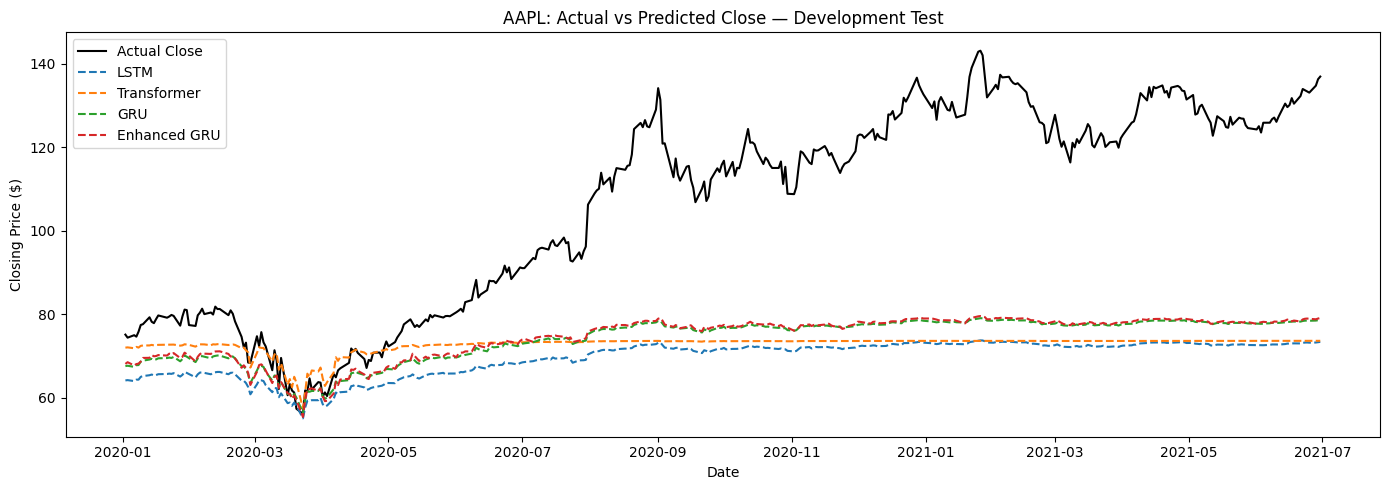

In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Retrieve training-only normalization statistics
close_index = columns_to_normalize.index("Close")
close_mean = mean[close_index].item()
close_std = std[close_index].item()

def to_original_prices(values):
    values = np.asarray(values).reshape(-1)
    return values * close_std + close_mean

# Verify the test tensors match the shared split
actual = to_original_prices(
    test_target.detach().cpu().numpy()
)

assert len(actual) == len(test_raw)
assert np.allclose(
    actual,
    test_raw["Close"].to_numpy(),
    atol=1e-4
), "Test tensors do not match the shared AAPL split."

def calculate_metrics(predictions):
    predicted = to_original_prices(predictions)

    if len(predicted) != len(actual):
        raise ValueError(
            "Predictions do not match test observations"
        )

    mse = mean_squared_error(
        actual, predicted
    )

    mape = np.mean(
        np.abs(
            (actual - predicted) /
            np.maximum(np.abs(actual), 1e-8)
        )
    ) * 100

    return {
        "MAE ($)": mean_absolute_error(
            actual, predicted
        ),
        "MSE ($²)": mse,
        "RMSE ($)": np.sqrt(mse),
        "MAPE (%)": mape,
        "R²": r2_score(actual, predicted)
    }

comparison = pd.DataFrame({
    "LSTM": calculate_metrics(
        test_predictions_lstm
    ),
    "Transformer": calculate_metrics(
        test_predictions
    ),
    "GRU": calculate_metrics(
        gru_predictions
    ),
    "Enhanced GRU": calculate_metrics(
        enhanced_gru_predictions
    )
}).T

print("\nMODEL PERFORMANCE COMPARISON")
print(comparison.round(4))

# Compare all four predictions in original price units
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(test_raw.index, actual, color="black", label="Actual Close")
for label, predictions in {
    "LSTM": test_predictions_lstm,
    "Transformer": test_predictions,
    "GRU": gru_predictions,
    "Enhanced GRU": enhanced_gru_predictions
}.items():
    plt.plot(test_raw.index, to_original_prices(predictions),
             linestyle="--", label=label)
plt.xlabel("Date")
plt.ylabel("Closing Price ($)")
plt.title("AAPL: Actual vs Predicted Close — Development Test")
plt.legend()
plt.tight_layout()
plt.show()


## Optional final validation — do not enable during development
Only after all settings and model-selection decisions are frozen, change `RUN_FINAL_VALIDATION` to `True` and run this cell once. The results are separate from the development-test comparison. Do not tune models after viewing this table. If the validation data has previously influenced decisions, a new untouched holdout is needed for an independent final assessment.

In [17]:
RUN_FINAL_VALIDATION = False

if RUN_FINAL_VALIDATION:
    val_data = (val_raw - mean.numpy()) / std.numpy()
    val_features = torch.tensor(
        val_data[feature_columns].to_numpy(), dtype=torch.float32
    )
    val_news = make_news_features(val_raw.index, scored_news)
    val_features_enhanced = torch.cat(
        [val_features, news_tensor(val_news)], dim=1
    )
    val_actual = val_raw["Close"].to_numpy()

    validation_predictions = {}
    for name, fitted_model, inputs in [
        ("LSTM", model_lstm, val_features),
        ("Transformer", transformer_model, val_features),
        ("GRU", model_gru, val_features),
        ("Enhanced GRU", model_gru_enhanced, val_features_enhanced)
    ]:
        fitted_model.eval()
        with torch.no_grad():
            predictions = fitted_model(inputs.unsqueeze(1)).squeeze(1).cpu().numpy()
        validation_predictions[name] = to_original_prices(predictions)

    def validation_metrics(predicted):
        mse = mean_squared_error(val_actual, predicted)
        return {
            "MAE ($)": mean_absolute_error(val_actual, predicted),
            "MSE ($²)": mse,
            "RMSE ($)": np.sqrt(mse),
            "MAPE (%)": np.mean(
                np.abs(val_actual - predicted) /
                np.maximum(np.abs(val_actual), 1e-8)
            ) * 100,
            "R²": r2_score(val_actual, predicted)
        }

    validation_comparison = pd.DataFrame({
        name: validation_metrics(predictions)
        for name, predictions in validation_predictions.items()
    }).T

    print("FINAL HELD-OUT VALIDATION RESULTS")
    print(validation_comparison.round(4))
else:
    print("Final validation remains reserved.")


Final validation remains reserved.
